# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

In [33]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

In [34]:
img = cv.imread('periodic_noise.JPG', cv.IMREAD_GRAYSCALE)
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

In [35]:
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

In [36]:
sigma = 30 
x, y = np.meshgrid(np.arange(0, cols, 1), np.arange(0, rows, 1))
dist_sq = (x - ccol)**2 + (y - crow)**2

In [37]:
gaussian_lpf = np.exp(-dist_sq / (2 * (sigma ** 2)))
gaussian_hpf = 1 - gaussian_lpf

In [38]:
mask_hpf = np.zeros((rows, cols, 2), np.float32)
mask_hpf[:, :, 0] = gaussian_hpf
mask_hpf[:, :, 1] = gaussian_hpf

In [39]:
fshift_hpf = dft_shift * mask_hpf
filtering_magn_hpf = 20 * np.log(cv.magnitude(fshift_hpf[:, :, 0], fshift_hpf[:, :, 1]) + 1)

In [40]:
f_ishift_hpf = np.fft.ifftshift(fshift_hpf)
img_hpf = cv.idft(f_ishift_hpf)
img_hpf = cv.magnitude(img_hpf[:, :, 0], img_hpf[:, :, 1])

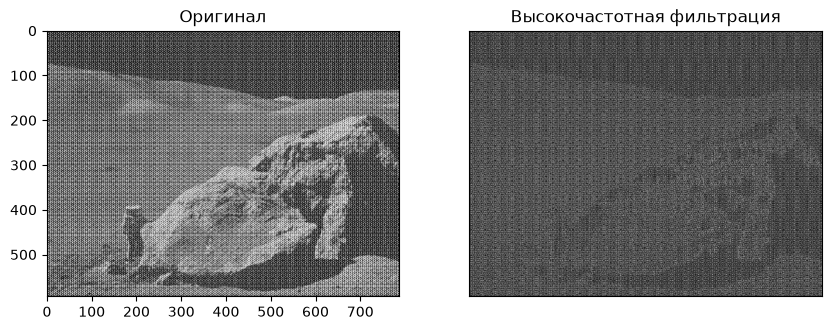

In [41]:
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original')
plt.subplot(122), plt.imshow(img_hpf, cmap='gray')
plt.title('Высокочастотная фильтрация'), plt.xticks([]), plt.yticks([])
plt.show()

# Реализуйте вычисление свертки с помощью преобразования Фурье

In [42]:
k_size = 15
kernel = np.ones((k_size, k_size), np.float32) / (k_size ** 2)

In [43]:
ih, iw = img.shape
kh, kw = kernel.shape
fh, fw = ih + kh - 1, iw + kw - 1
_img    = np.fft.fft2(img.astype(np.float32),    s=(fh, fw))
_kernel = np.fft.fft2(kernel.astype(np.float32), s=(fh, fw))
full = np.real(np.fft.ifft2(_img * _kernel))
ph, pw = kh // 2, kw // 2

In [44]:
img_fft = full[ph:ph+ih, pw:pw+iw]

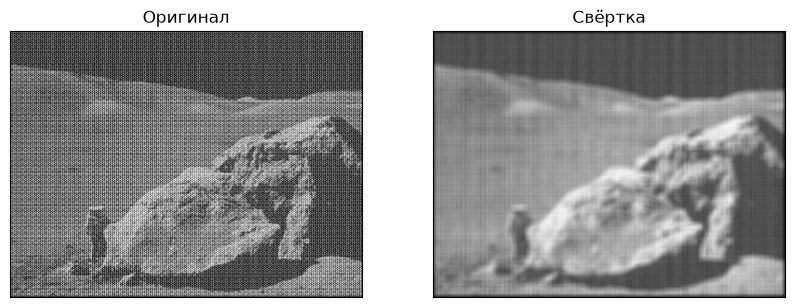

In [45]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray')
plt.title('Оригинал'), plt.xticks([]), plt.yticks([])
plt.subplot(1, 2, 2), plt.imshow(img_fft, cmap='gray')
plt.title('Свёртка'), plt.xticks([]), plt.yticks([])
plt.show()

# Реализуйте удаление периодического шума с помощью преобразования Фурье

In [128]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
magnitude = cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])
log_spectrum = 20 * np.log(magnitude + 1)

In [129]:
spectrum_analysis = log_spectrum.copy()
y, x = np.ogrid[:rows, :cols]
center_area = ((x - ccol)**2 + (y - crow)**2) <= 25**2
spectrum_analysis[center_area] = 0

In [130]:
threshold = np.percentile(spectrum_analysis, 99.8)
noise_peaks = (spectrum_analysis > threshold).astype(np.uint8)

In [131]:
kernel_dilate = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5))
notch_mask = 1 - cv.dilate(noise_peaks, kernel_dilate)

In [132]:
fshift_filtered = dft_shift * notch_mask[:, :, np.newaxis]
filtered_spectrum = 20 * np.log(cv.magnitude(fshift_filtered[:, :, 0], fshift_filtered[:, :, 1]) + 1)

In [133]:
f_ishift = np.fft.ifftshift(fshift_filtered)
img_denoised = cv.idft(f_ishift)
img_denoised = cv.magnitude(img_denoised[:, :, 0], img_denoised[:, :, 1])

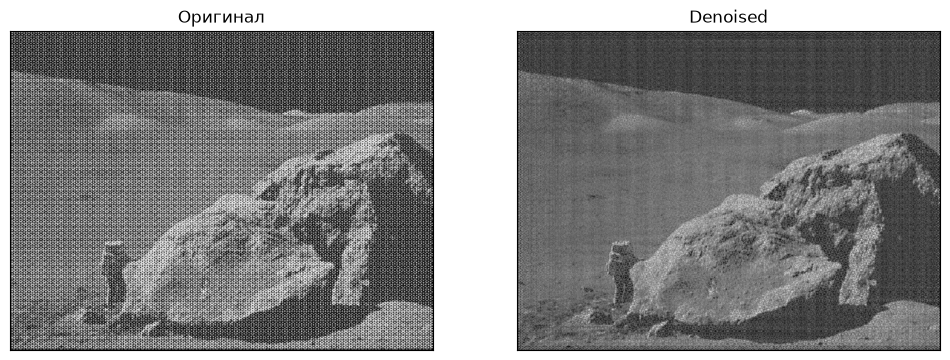

In [135]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray')
plt.title('Оригинал'), plt.xticks([]), plt.yticks([])
plt.subplot(1, 2, 2), plt.imshow(img_denoised, cmap='gray')
plt.title('Denoised'), plt.xticks([]), plt.yticks([])
plt.show()